In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
# Create the transaction dataset
np.random.seed(42)

n = 5000

In [4]:
# 10% fraud
fraud = np.random.rand(n) < 0.10

In [5]:
# Average transaction amount
avg_amount = np.random.lognormal(4, 0.9, n)

In [6]:
# Transaction amount
amount = np.where(
    fraud,
    avg_amount * np.random.lognormal(0.9, 0.35, n),
    avg_amount * np.random.lognormal(0.0, 0.3, n)
)

In [7]:
# Transaction hour
hour = np.where(
    fraud & (np.random.rand(n) < 0.6),
    np.random.randint(0, 6, n),
    np.random.randint(6, 24, n)
)

In [8]:
# Distance from usual location
distance = np.where(
    fraud,
    np.random.exponential(13, n),
    np.random.exponential(10, n)
)

In [9]:
# Number of transactions in last 24 hours
txn_24h = np.where(
    fraud,
    np.random.poisson(3, n),
    np.random.poisson(2, n)
)

In [10]:
# Create DataFrame
data = pd.DataFrame({
    'amount': amount,
    'avg_amount': avg_amount,
    'hour': hour,
    'distance_km': distance,
    'txn_last_24h': txn_24h,
    'Class': fraud.astype(int)
})

In [11]:
print("Class distribution:")
print(data['Class'].value_counts())

Class distribution:
Class
0    4475
1     525
Name: count, dtype: int64


In [37]:
def evaluate(df):

    X = df.drop('Class', axis=1)
    y = df['Class']

    X_tr, X_te, y_tr, y_te = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Scale features
    sc = StandardScaler()

    X_tr = sc.fit_transform(X_tr)
    X_te = sc.transform(X_te)

    # Logistic Regression
    model = LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    )

    model.fit(X_tr, y_tr)

    pred = model.predict(X_te)

    return [
        accuracy_score(y_te, pred),
        precision_score(y_te, pred),
        recall_score(y_te, pred),
        f1_score(y_te, pred)
    ]


In [38]:
# BEFORE feature engineering
before = evaluate(data)

In [39]:
# Step 4: Feature engineering
eng = data.copy()

In [40]:
# Ratio between current amount and average amount
eng['amount_ratio'] = (
    eng['amount'] / eng['avg_amount']
)

In [41]:
# Whether transaction happened at night
eng['is_night'] = (
    eng['hour'] < 6
).astype(int)

In [42]:
# Logarithm of transaction amount
eng['log_amount'] = np.log1p(
    eng['amount']
)

In [43]:
# Interaction between distance and transaction frequency
eng['distance_x_txn'] = (
    eng['distance_km'] *
    eng['txn_last_24h']
)

In [44]:
# Step 5: AFTER feature engineering
after = evaluate(eng)

In [45]:
# Compare results
names = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-score'
]

results = pd.DataFrame(
    {
        'Before': before,
        'After': after
    },
    index=names
)

In [46]:
print("\nModel Performance:")
print(results.round(3))


Model Performance:
           Before  After
Accuracy    0.940  0.963
Precision   0.660  0.758
Recall      0.886  0.952
F1-score    0.756  0.844


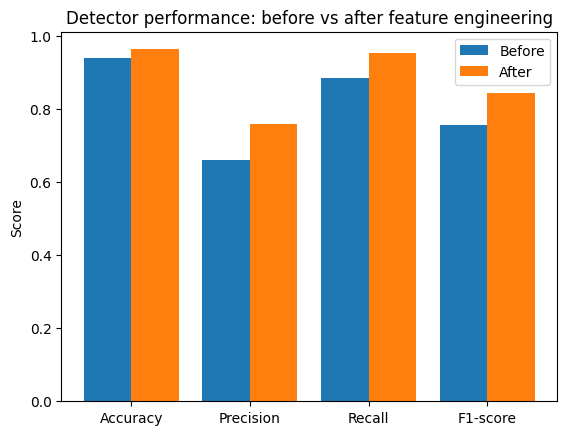

In [47]:
# Plot comparison
x = np.arange(4)

plt.bar(
    x - 0.2,
    before,
    0.4,
    label='Before'
)

plt.bar(
    x + 0.2,
    after,
    0.4,
    label='After'
)

plt.xticks(x, names)

plt.ylabel('Score')
plt.legend()

plt.title(
    'Detector performance: before vs after feature engineering'
)

plt.show()